In [1]:
# convergence analysis for the montecarlo option pricing along with standard error
import sys

from pathlib import Path
sys.path.append(str(Path.cwd().parent))
from src import monte_carlo as mc

simulation_counts = [1000, 5000, 10000, 50000, 100000, 500000]
option_price = []
standard_error = []
for N in simulation_counts:
    price, se = mc.monte_carlo_option_price(100, 100, 1, 0.05, 0.20, N, "call")
    option_price.append(price)
    standard_error.append(se)

print (simulation_counts, option_price, standard_error)

[1000, 5000, 10000, 50000, 100000, 500000] [np.float64(10.656886694897748), np.float64(10.544828510862446), np.float64(10.437394528673076), np.float64(10.53459785111219), np.float64(10.454546370085236), np.float64(10.459667028746994)] [np.float64(0.4579298080218982), np.float64(0.21543069610231275), np.float64(0.14590428512569492), np.float64(0.06638034998925028), np.float64(0.04671485262899866), np.float64(0.020872139164435678)]


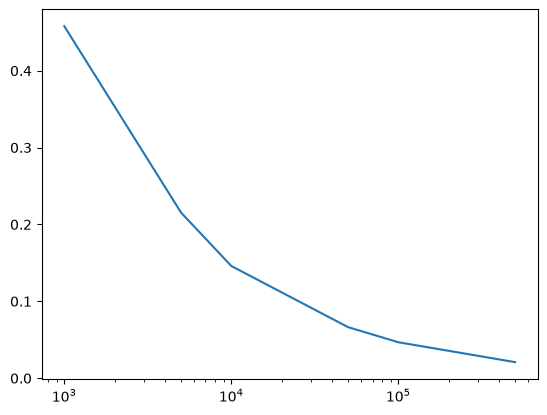

In [2]:
import matplotlib.pyplot as plt
import numpy as np

xpoints = simulation_counts
ypoints = standard_error

plt.plot(xpoints, ypoints)
plt.xscale("log")
plt.show()

10.450583572185565
[np.float64(0.20630312271218365), np.float64(0.09424493867688177), np.float64(0.013189043512488396), np.float64(0.08401427892662561), np.float64(0.003962797899671244), np.float64(0.00908345656142906)]


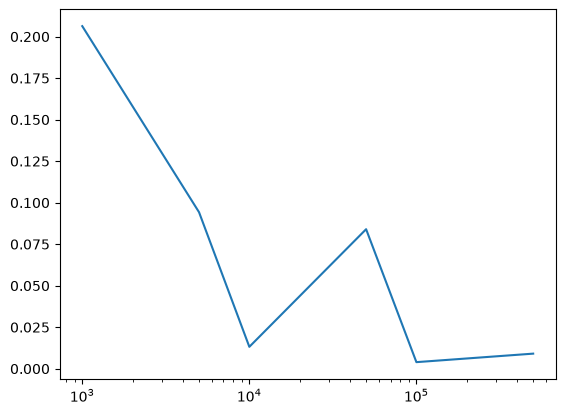

In [3]:
from src import black_scholes as bs
benchmark_price = black_scholes_price = bs.black_scholes_price(100, 100, 1, 0.05, 0.2, "call")
print(benchmark_price)

absolute_errors = []
for price in option_price:
    absolute_errors.append(abs(price-benchmark_price))
print(absolute_errors)

xpoints = simulation_counts
ypoints = absolute_errors

plt.plot(xpoints, ypoints)
plt.xscale("log")
plt.show()


[np.float64(9.759360763727488), np.float64(10.122592105337521), np.float64(10.151427384636651), np.float64(10.404494755852095), np.float64(10.362986941389302), np.float64(10.418758387704392)]
[np.float64(11.55441262606801), np.float64(10.967064916387372), np.float64(10.723361672709501), np.float64(10.664700946372285), np.float64(10.54610579878117), np.float64(10.500575669789596)]


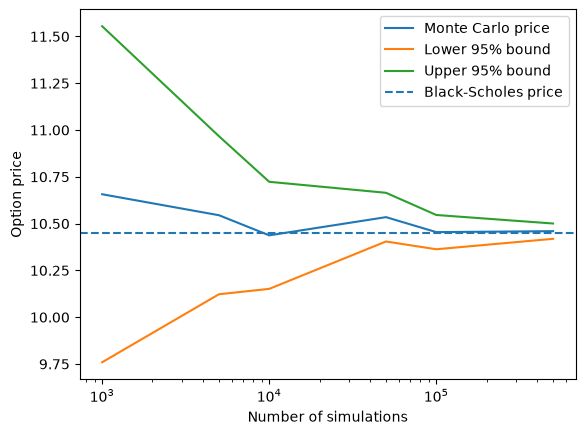

In [4]:
from scipy.stats import norm

def monte_carlo_confidence_interval(option_prices, standard_errors, confidence_level):
    lower_bounds = []
    upper_bounds = []

    z = norm.ppf((1 + confidence_level) / 2)

    for price, se in zip(option_prices, standard_errors):
        lower_bounds.append(price - z * se)
        upper_bounds.append(price + z * se)

    return lower_bounds, upper_bounds

confidence_level = 0.95

lower_bounds, upper_bounds = monte_carlo_confidence_interval(option_price,standard_error,confidence_level)
print(lower_bounds)
print(upper_bounds)

xpoints = simulation_counts

plt.plot(xpoints, option_price, label="Monte Carlo price")
plt.plot(xpoints, lower_bounds, label="Lower 95% bound")
plt.plot(xpoints, upper_bounds, label="Upper 95% bound")

plt.axhline(y=benchmark_price,linestyle="--",label="Black-Scholes price")
plt.xscale("log")
plt.xlabel("Number of simulations")
plt.ylabel("Option price")
plt.legend()
plt.show()

[1000, 5000, 10000, 50000, 100000, 500000] [np.float64(10.656886694897748), np.float64(10.544828510862446), np.float64(10.437394528673076), np.float64(10.53459785111219), np.float64(10.454546370085236), np.float64(10.459667028746994)] [np.float64(0.4579298080218982), np.float64(0.21543069610231275), np.float64(0.14590428512569492), np.float64(0.06638034998925028), np.float64(0.04671485262899866), np.float64(0.020872139164435678)]


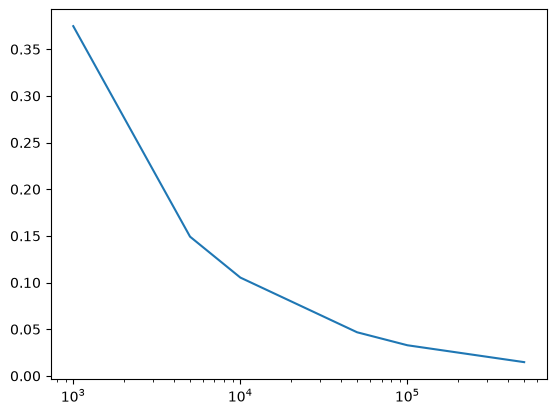

In [5]:
# TESTING THE CONVERGENCE OF THE ANTITHETIC FUNCTION INSTEAD
simulation_counts = [1000, 5000, 10000, 50000, 100000, 500000]
antithetic_option_price = []
antithetic_standard_error = []
for N in simulation_counts:
    price, se = mc.antithetic_monte_carlo_option_price(100, 100, 1, 0.05, 0.20, N, "call")
    antithetic_option_price.append(price)
    antithetic_standard_error.append(se)

print (simulation_counts, option_price, standard_error)

import matplotlib.pyplot as plt # plots number of simulations vs the standard error
import numpy as np

xpoints = simulation_counts
ypoints = antithetic_standard_error

plt.plot(xpoints, ypoints)
plt.xscale("log")
plt.show()

[np.float64(0.20630312271218365), np.float64(0.09424493867688177), np.float64(0.013189043512488396), np.float64(0.08401427892662561), np.float64(0.003962797899671244), np.float64(0.00908345656142906)]


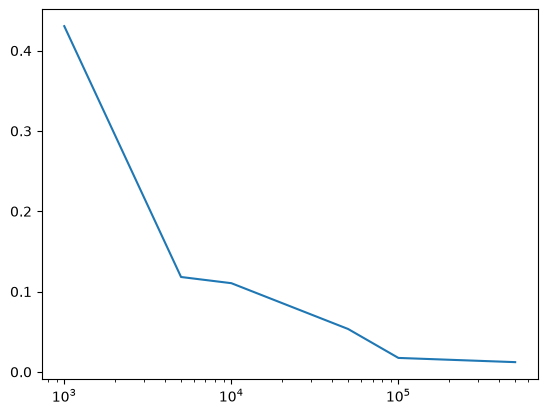

In [6]:
antithetic_absolute_errors = [] # calculates the absolute error against the benchmark price calculated from bs
for price in antithetic_option_price:
    antithetic_absolute_errors.append(abs(price-benchmark_price))
print(absolute_errors)

xpoints = simulation_counts
ypoints = antithetic_absolute_errors

plt.plot(xpoints, ypoints)
plt.xscale("log")
plt.show()


[np.float64(10.146606121950645), np.float64(10.04003194167053), np.float64(10.35457065313331), np.float64(10.412438509452995), np.float64(10.403665416509499), np.float64(10.409561985348796)]
[np.float64(11.615557602054258), np.float64(10.624801450188002), np.float64(10.767528547568302), np.float64(10.59558296771093), np.float64(10.532297862793934), np.float64(10.467296253100441)]


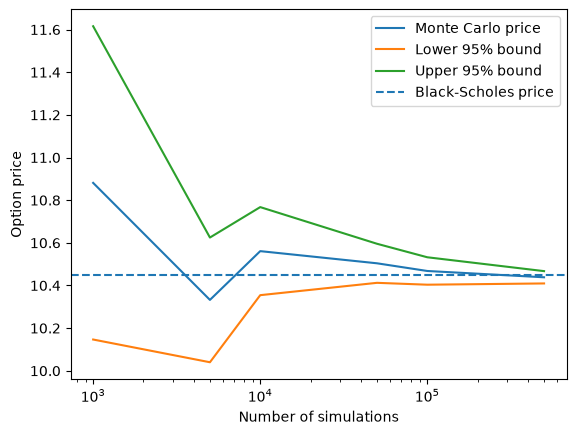

In [7]:
def monte_carlo_confidence_interval(antithetic_option_prices, antithetic_standard_errors, confidence_level):
    lower_bounds = []
    upper_bounds = []

    z = norm.ppf((1 + confidence_level) / 2)

    for price, se in zip(antithetic_option_prices, antithetic_standard_errors):
        lower_bounds.append(price - z * se)
        upper_bounds.append(price + z * se)

    return lower_bounds, upper_bounds

confidence_level = 0.95

lower_bounds, upper_bounds = monte_carlo_confidence_interval(antithetic_option_price,antithetic_standard_error,confidence_level)
print(lower_bounds)
print(upper_bounds)

xpoints = simulation_counts

plt.plot(xpoints, antithetic_option_price, label="Monte Carlo price")
plt.plot(xpoints, lower_bounds, label="Lower 95% bound")
plt.plot(xpoints, upper_bounds, label="Upper 95% bound")

plt.axhline(y=benchmark_price,linestyle="--",label="Black-Scholes price")
plt.xscale("log")
plt.xlabel("Number of simulations")
plt.ylabel("Option price")
plt.legend()
plt.show()

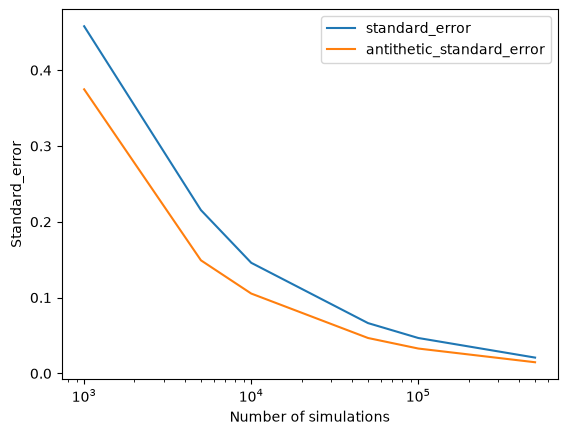

In [8]:
# normal vs antithetic convergence analysis
xpoints = simulation_counts
plt.plot(xpoints, standard_error, label = "standard_error")
plt.plot(xpoints, antithetic_standard_error, label = "antithetic_standard_error")
plt.xscale("log")
plt.xlabel("Number of simulations")
plt.ylabel("Standard_error")
plt.legend()
plt.show()

call benchmark: 10.450584
  N=5     price=10.805934  abs error=0.355350
  N=10    price=10.253409  abs error=0.197175
  N=20    price=10.351260  abs error=0.099323
  N=50    price=10.410692  abs error=0.039892
  N=100   price=10.430612  abs error=0.019972
  N=200   price=10.440591  abs error=0.009992
  N=500   price=10.446585  abs error=0.003998
  N=1000  price=10.448584  abs error=0.001999
put benchmark: 5.573526
  N=5     price=5.928876  abs error=0.355350
  N=10    price=5.376351  abs error=0.197175
  N=20    price=5.474203  abs error=0.099323
  N=50    price=5.533634  abs error=0.039892
  N=100   price=5.553554  abs error=0.019972
  N=200   price=5.563534  abs error=0.009992
  N=500   price=5.569528  abs error=0.003998
  N=1000  price=5.571527  abs error=0.001999


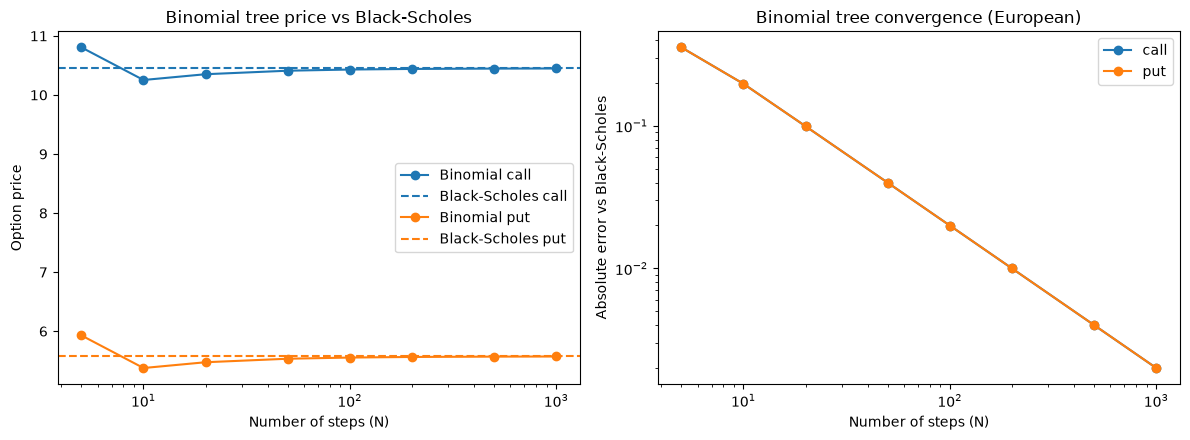

In [ ]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

#binomial tree convergence


import numpy as np
import matplotlib.pyplot as plt
from src import binomial_tree as bt
from src import black_scholes as bs

S, K, T, r, sigma = 100, 100, 1, 0.05, 0.20
step_counts = [5, 10, 20, 50, 100, 200, 500, 1000]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for option_type in ["call", "put"]:
    benchmark = bs.black_scholes_price(S, K, T, r, sigma, option_type)
    tree_prices = [
        bt.binomial_option_price(S, K, T, r, sigma, N, option_type)
        for N in step_counts
    ]
    errors = [abs(p - benchmark) for p in tree_prices]

    # left panel: tree price vs Black-Scholes
    line, = axes[0].plot(step_counts, tree_prices, marker="o",
                         label=f"Binomial {option_type}")
    axes[0].axhline(benchmark, linestyle="--", color=line.get_color(),
                    label=f"Black-Scholes {option_type}")

    # right panel: absolute error
    axes[1].plot(step_counts, errors, marker="o", label=option_type)

    print(option_type, "benchmark:", round(benchmark, 6))
    for N, p, e in zip(step_counts, tree_prices, errors):
        print(f"  N={N:<5} price={p:.6f}  abs error={e:.6f}")

axes[0].set_xscale("log")
axes[0].set_xlabel("Number of steps (N)")
axes[0].set_ylabel("Option price")
axes[0].set_title("Binomial tree price vs Black-Scholes")
axes[0].legend()

axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Number of steps (N)")
axes[1].set_ylabel("Absolute error vs Black-Scholes")
axes[1].set_title("Binomial tree convergence (European)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# LSM tests setup and references
import sys, time
from pathlib import Path
sys.path.append(str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from longstaff_schwartz import lsm_american_price
from binomial_tree import american_binomial_option_price
from black_scholes import black_scholes_price

S, K, T, r, sigma = 100, 100, 1, 0.05, 0.20
option_type = "put"
SEED = 42   # fixed seed so every run of this notebook gives the same numbers

tree_ref = american_binomial_option_price(S, K, T, r, sigma, 500, option_type)
euro_ref = black_scholes_price(S, K, T, r, sigma, option_type)
print("Binomial American put (N=500):", tree_ref)
print("Black-Scholes European put:   ", euro_ref)

In [ ]:
#lsm baseline checks
cases = {
    "Paper case (S=36, K=40, r=6%)": (36, 40, 1, 0.06, 0.20),
    "ATM (S=K=100, r=5%)":           (100, 100, 1, 0.05, 0.20),
}

rows = []
for name, (S_, K_, T_, r_, sig_) in cases.items():
    np.random.seed(SEED)
    lsm_p, lsm_se = lsm_american_price(S_, K_, T_, r_, sig_, 100000, 50, "put")
    tree_p = american_binomial_option_price(S_, K_, T_, r_, sig_, 500, "put")
    euro_p = black_scholes_price(S_, K_, T_, r_, sig_, "put")
    rows.append({
        "Case": name,
        "LSM": lsm_p,
        "LSM SE": lsm_se,
        "Binomial (American)": tree_p,
        "BS (European)": euro_p,
        "LSM - Binomial": lsm_p - tree_p,
        "Rel. diff %": 100 * (lsm_p - tree_p) / tree_p,
    })

pd.DataFrame(rows).round(4)

In [ ]:
#lsm number of exercise dates
steps_list = [5, 10, 25, 50, 100]
lsm_prices, lsm_ses, tree_same_dates = [], [], []

for n_steps in steps_list:
    np.random.seed(SEED)
    p, se = lsm_american_price(S, K, T, r, sigma, 100000, n_steps, option_type)
    lsm_prices.append(p)
    lsm_ses.append(se)
    tree_same_dates.append(
        american_binomial_option_price(S, K, T, r, sigma, n_steps, option_type)
    )

plt.errorbar(steps_list, lsm_prices, yerr=1.96 * np.array(lsm_ses),
             marker="o", capsize=3, label="LSM (95% CI)")
plt.plot(steps_list, tree_same_dates, marker="s", linestyle=":",
         label="Binomial, same number of dates")
plt.axhline(tree_ref, linestyle="--", color="red", label="Binomial N=500")
plt.axhline(euro_ref, linestyle="--", color="grey", label="Black-Scholes European")
plt.xscale("log")
plt.xlabel("Number of exercise dates")
plt.ylabel("American put price")
plt.title("LSM price vs number of exercise dates")
plt.legend()
plt.show()

In [ ]:
#lsm basis function degree
degrees = [1, 2, 3, 4, 5, 6]
deg_prices, deg_ses = [], []

for d in degrees:
    np.random.seed(SEED)   # same seed, so every degree sees identical paths
    p, se = lsm_american_price(S, K, T, r, sigma, 100000, 50, option_type, degree=d)
    deg_prices.append(p)
    deg_ses.append(se)

plt.errorbar(degrees, deg_prices, yerr=1.96 * np.array(deg_ses),
             marker="o", capsize=3, label="LSM (95% CI)")
plt.axhline(tree_ref, linestyle="--", color="red", label="Binomial N=500")
plt.xlabel("Laguerre basis degree")
plt.ylabel("American put price")
plt.title("LSM price vs regression basis degree")
plt.legend()
plt.show()

In [ ]:
#lsm moneyness table
spots = [80, 90, 100, 110, 120]   # ITM, ITM, ATM, OTM, OTM for a put with K=100
rows = []
for S_ in spots:
    np.random.seed(SEED)
    lsm_p, lsm_se = lsm_american_price(S_, K, T, r, sigma, 100000, 50, "put")
    tree_p = american_binomial_option_price(S_, K, T, r, sigma, 500, "put")
    euro_p = black_scholes_price(S_, K, T, r, sigma, "put")
    rows.append({
        "Spot": S_,
        "LSM": lsm_p,
        "LSM SE": lsm_se,
        "Binomial (American)": tree_p,
        "BS (European)": euro_p,
        "Early-exercise premium": tree_p - euro_p,
        "LSM - Binomial": lsm_p - tree_p,
        "Rel. diff %": 100 * (lsm_p - tree_p) / tree_p,
    })

pd.DataFrame(rows).round(4)

In [ ]:
#lsm noise vs bias
path_counts = [1000, 5000, 10000, 50000, 100000, 200000]
path_prices, path_ses = [], []

for n in path_counts:
    np.random.seed(SEED)
    p, se = lsm_american_price(S, K, T, r, sigma, n, 50, option_type)
    path_prices.append(p)
    path_ses.append(se)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].errorbar(path_counts, path_prices, yerr=1.96 * np.array(path_ses),
                 marker="o", capsize=3, label="LSM (95% CI)")
axes[0].axhline(tree_ref, linestyle="--", color="red", label="Binomial N=500")
axes[0].set_xscale("log")
axes[0].set_xlabel("Number of paths")
axes[0].set_ylabel("American put price")
axes[0].set_title("LSM price vs number of paths")
axes[0].legend()

ref = path_ses[0] * np.sqrt(path_counts[0] / np.array(path_counts))
axes[1].plot(path_counts, path_ses, marker="o", label="LSM standard error")
axes[1].plot(path_counts, ref, linestyle="--", color="grey", label="1/sqrt(n) reference")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Number of paths")
axes[1].set_ylabel("Standard error")
axes[1].set_title("LSM standard error vs number of paths")
axes[1].legend()

plt.tight_layout()
plt.show()

In [9]:
import os
print(os.getcwd())

c:\Programming work and projects\options-pricing\notebooks
